# [12.4] Visual Token Flow in Real VLMs (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part4_visual_token_flow/12.4_Visual_Token_Flow_in_Real_VLMs_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part4_visual_token_flow/12.4_Visual_Token_Flow_in_Real_VLMs_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-12-4) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

Look at a four-patch image with a red object at the top left and a blue distractor at the bottom right. Ask “what colour is the top-left object?” Now change only that object to blue. If you replace the answer position before it has read the image, should the answer change? What if you replace all visual positions instead?

By the end of this notebook, you will have shown exactly why full-sequence and last-position interventions differ in a visible image-question residual-flow organism, using a layer-by-position recovery heatmap with object and background controls. Then you will map that intervention contract to the real Qwen2.5-VL, PaliGemma, LLaVA-OneVision and Molmo families without pretending a source-level map qualifies their hooks.

The executed model here is a small specified attention route, not pretrained weights or a transformer trained to reason. Its point is that we can calculate the correct result independently. [12.3] supplies the fuller MiniVLM/GPT-2/Qwen reference; [1.2] hooks and [8.1] patching are prerequisites. Native adapter runs, checkpoints and real-model mechanism claims remain pending.

## Content & Learning Objectives

### 1️⃣ Write down the token contract

> ##### Learning Objectives
>
> - Build image patches and an explicit image/question/answer layout before choosing a hook.

### 2️⃣ Follow a visible information route

> ##### Learning Objectives
>
> - Implement attention, attention knockout and a tiny residual-flow model with cached boundaries.

### 3️⃣ Patch the whole question, not just its answer

> ##### Learning Objectives
>
> - Compare object, background, full-sequence and final-position patching on matched counterfactuals.

### 4️⃣ Bridge to real adapters and conditional decoding

> ##### Learning Objectives
>
> - Implement a layout check and activation-conditioned decoder; map the exact contract to released VLM APIs.

## Setup code

This study edition uses NumPy, Matplotlib and Pillow already installed in the course environment. All arrays are CPU float64, all examples are deterministic, and no model or network access occurs. Work in the full local checkout. Ordinary mathematical fixtures are guided practice, with no untouched evaluation split implied.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapter12_vlm_interpretability").exists())
exercises_dir = root_dir / "chapter12_vlm_interpretability" / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
from part4_visual_token_flow import tests as tests
from part4_visual_token_flow import utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=3, suppress=True)

# 1️⃣ Write down the token contract

> ##### Learning Objectives
>
> - Build image patches and an explicit image/question/answer layout before choosing a hook.

An intervention is defined by a **boundary**, a **position set** and a **donor**. “Patch layer 5” is incomplete: is that the decoder input, its residual output or the result after a modality-specific addition? A visual crop may create several tokens, and a processor may insert delimiters that are not image content.

Our organism has six positions: four visual patches in row-major order, one question and one answer. Each residual vector has six coordinates: two colour channels followed by four spatial coordinates. Position identity is separate from content. The rendered pixels are pooled into a 2×2 patch grid; mean red and blue channels are the explicit visual features.

### Exercise - implement `grid_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

For image arrays `(batch,height,width,3)`, return mean red and blue channels per square-grid patch, shape `(batch,grid*grid,2)`, in row-major order. Require both spatial sizes to be divisible by `grid`.

In [2]:
def grid_features(images, grid=2):
    batch,height,width,_ = images.shape
    if height % grid or width % grid:
        raise ValueError("Image dimensions must divide the grid")
    patches = images.reshape(batch,grid,height//grid,grid,width//grid,3).transpose(0,1,3,2,4,5)
    return patches.mean(axis=(3,4))[..., [0,2]].reshape(batch,grid*grid,2)


tests.test_grid_features(grid_features)

All tests in test_grid_features passed!


<details>
<summary>Hint</summary>

Make row-grid and column-grid axes adjacent before flattening them.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_grid_features passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `assemble_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Assemble `(batch,6,6)` from four colour-feature vectors and one queried patch index per example. Put identity spatial codes at visual positions, the queried spatial code at position4 and zeros at answer position5.

In [3]:
def assemble_tokens(features, query_patch):
    h = np.zeros((len(features),6,6))
    h[:,:4,:2] = features
    h[:,:4,2:] = np.eye(4)[None]
    h[:,4,2:] = np.eye(4)[query_patch]
    return h


tests.test_assemble_tokens(assemble_tokens)

All tests in test_assemble_tokens passed!


<details>
<summary>Hint</summary>

Use one-hot spatial codes, not a colour hint in the question token.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_assemble_tokens passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `validate_layout`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Return an immutable tuple of image-token indices after checking uniqueness, bounds and exclusion of the answer position. These are mandatory layout checks for any adapter; do not infer image positions from sequence length alone.

In [4]:
def validate_layout(sequence_length, image_positions, answer_position):
    positions = tuple(int(i) for i in image_positions)
    if len(set(positions)) != len(positions) or any(i < 0 or i >= sequence_length for i in positions):
        raise ValueError("Image positions must be unique and in sequence bounds")
    if answer_position < 0 or answer_position >= sequence_length or answer_position in positions:
        raise ValueError("Answer position must be separate and in bounds")
    return positions


tests.test_validate_layout(validate_layout)

All tests in test_validate_layout passed!


<details>
<summary>Hint</summary>

Reject a duplicated visual token even when the set of indices would otherwise look plausible.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_validate_layout passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

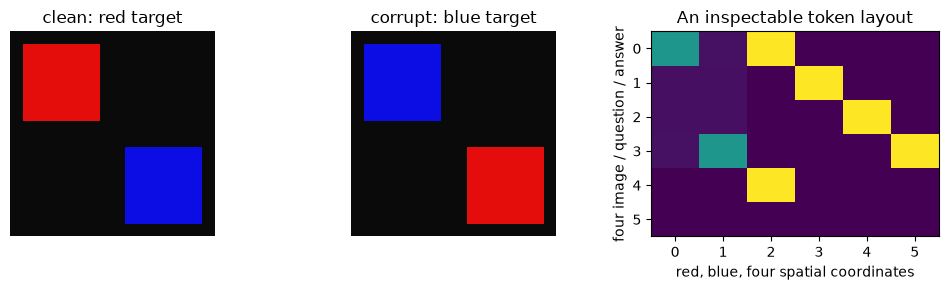

In [5]:
images = np.stack([utils.render_grid(0,c) for c in [0,1]])
features = grid_features(images)
initial = assemble_tokens(features,np.array([0,0]))
validate_layout(initial.shape[1],range(4),5)
fig,axes=plt.subplots(1,3,figsize=(10,3))
for ax,image,title in zip(axes[:2],images,["clean: red target","corrupt: blue target"]):
    ax.imshow(image);ax.set_title(title);ax.axis("off")
axes[2].imshow(initial[0],aspect="auto",cmap="viridis");axes[2].set(xlabel="red, blue, four spatial coordinates",ylabel="four image / question / answer",title="An inspectable token layout")
plt.tight_layout();plt.show()

<details><summary>Help - matched counterfactuals</summary>

Both examples use the same patch grid, question position and answer position. Our renderer also changes the opposite-colour distractor when the target colour changes; that fact means full-sequence interventions include more than one visual difference. The object-only versus matched background condition isolates the queried patch in this known route. For a stronger natural-image experiment, freeze non-target pixels and document donor construction.

</details>

## Summary of 1️⃣

Token layout is data, not a constant to guess from a model family name. We have an exact correspondence for this controlled task.

# 2️⃣ Follow a visible information route

> ##### Learning Objectives
>
> - Implement attention, attention knockout and a tiny residual-flow model with cached boundaries.

Scaled dot-product attention is $\operatorname{softmax}(QK^T/\sqrt d)V$. The softmax normalises over **keys**, not query positions. Attention knockout sets specified key probabilities to zero and renormalises the remaining row; that operation changes the distribution over allowed keys and is different from zeroing value vectors.

Our visible route has three transitions. At transition0 the question reads the visual colours using its spatial query and scale16 (which yields a score of8 for the selected patch after dividing by $\sqrt4$). At transition1 the answer reads the question’s two colour coordinates. Transition2 is identity. The route is hand specified; no conclusion about the depth of a real model follows from its three stages.

### Exercise - implement `scaled_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Return attention-weighted values for `(queries,d)`, `(keys,d)`, `(keys,d_value)`. Subtract row maxima before exponentiation for numerical stability.

In [6]:
def scaled_attention(q, k, v):
    scores = q @ k.T / np.sqrt(q.shape[-1])
    weights = np.exp(scores - scores.max(axis=-1,keepdims=True))
    weights /= weights.sum(axis=-1,keepdims=True)
    return weights @ v


tests.test_scaled_attention(scaled_attention)

All tests in test_scaled_attention passed!


<details>
<summary>Hint</summary>

Softmax the query-by-key score rows, then multiply by values.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_scaled_attention passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `knockout_keys`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Given normalised attention rows and a boolean key mask, zero blocked keys and renormalise each row. Reject a row with no remaining probability mass. This function is a standalone attention intervention, used below to inspect the route.

In [7]:
def knockout_keys(probabilities, blocked):
    out = probabilities.copy()
    out[...,blocked] = 0
    mass = out.sum(axis=-1,keepdims=True)
    if np.any(mass <= 0):
        raise ValueError("No remaining attention mass")
    return out / mass


tests.test_knockout_keys(knockout_keys)

All tests in test_knockout_keys passed!


<details>
<summary>Hint</summary>

A nearly-zero remaining row is not permission to return an undefined all-zero attention distribution.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_knockout_keys passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `flow_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Copy the residual. At layer0 add spatial attention over the four visual colours to the question’s first two coordinates. At layer1 add question colour coordinates to the answer. At layer2 return the unchanged copy. Loop over examples to keep the route visible.

In [8]:
def flow_step(h, layer):
    out = h.copy()
    if layer == 0:
        for b in range(len(h)):
            out[b,4,:2] += scaled_attention(h[b,4:5,2:] * 16,h[b,:4,2:],h[b,:4,:2])[0]
    elif layer == 1:
        out[:,5,:2] += h[:,4,:2]
    elif layer != 2:
        raise ValueError("The organism has transitions 0,1,2")
    return out


tests.test_flow_step(flow_step)

All tests in test_flow_step passed!


<details>
<summary>Hint</summary>

Do not read from a partially updated residual. Both transitions use the pre-transition input.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_flow_step passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `run_flow`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Return independent copies of residuals at boundaries0,1,2,3 in an ordered dictionary. Boundary0 is the input; boundary3 is the final state. This boundary convention will also define intervention timing.

In [9]:
def run_flow(initial):
    cache = {0: initial.copy()}
    for layer in range(3):
        cache[layer+1] = flow_step(cache[layer],layer)
    return cache


tests.test_run_flow(run_flow)

All tests in test_run_flow passed!


<details>
<summary>Hint</summary>

Keep a copy at each boundary; reusing one mutable array would make every cache entry look final.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_run_flow passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

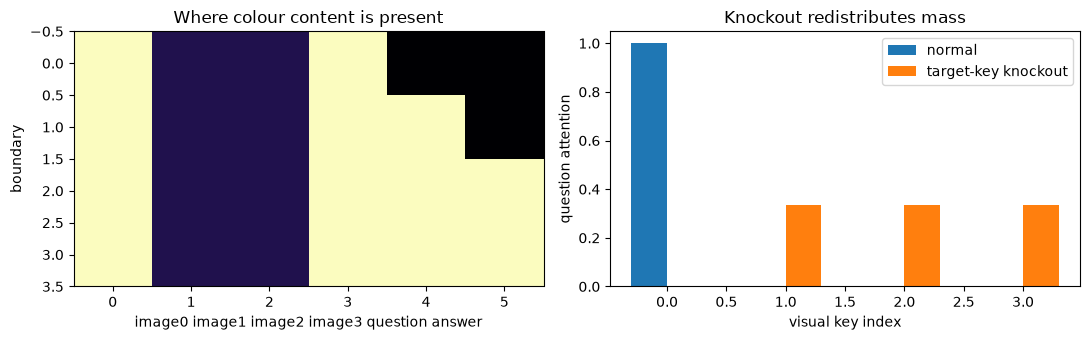

In [10]:
clean_cache = run_flow(initial[:1])
corrupt_cache = run_flow(initial[1:])
flow = np.stack([clean_cache[layer][0,:,:2].sum(axis=1) for layer in range(4)])
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].imshow(flow,aspect="auto",cmap="magma");axes[0].set(xlabel="image0 image1 image2 image3 question answer",ylabel="boundary",title="Where colour content is present")
attention = np.exp(np.array([[8.,0,0,0]]));attention/=attention.sum(axis=1,keepdims=True)
blocked = knockout_keys(attention,np.array([True,False,False,False]))
axes[1].bar(np.arange(4)-.15,attention[0],width=.3,label="normal");axes[1].bar(np.arange(4)+.15,blocked[0],width=.3,label="target-key knockout");axes[1].set(xlabel="visual key index",ylabel="question attention",title="Knockout redistributes mass");axes[1].legend()
plt.tight_layout();plt.show()

<details><summary>Help - present does not mean used</summary>

The image positions retain colour coordinates after the question has copied them. Their colour can still be decoded, even though the later transition never reads those positions. A lens or activation magnitude map cannot distinguish retained information from an active downstream route. Knockout probabilities show an available route, but answer effects are the stronger next check.

</details>

## Summary of 2️⃣

The exact route is image → question → answer. The cache makes the difference between available information and downstream use testable.

# 3️⃣ Patch the whole question, not just its answer

> ##### Learning Objectives
>
> - Compare object, background, full-sequence and final-position patching on matched counterfactuals.

### Exercise - implement `candidate_margin`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Given `(batch,vocab)` scores and per-example clean/corrupt candidate IDs, return clean-score minus corrupt-score for each example. Do not average until after normalising recoveries.

In [11]:
def candidate_margin(scores, clean_ids, corrupt_ids):
    rows = np.arange(len(scores))
    return scores[rows,clean_ids] - scores[rows,corrupt_ids]


tests.test_candidate_margin(candidate_margin)

All tests in test_candidate_margin passed!


<details>
<summary>Hint</summary>

Advanced indexing must pair one candidate ID with each example row.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_candidate_margin passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `replace_positions`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Copy the corrupted residual `(batch,sequence,d)` and replace all coordinates at the specified positions using the clean donor. Leave both inputs unchanged. Full-sequence patching means every sequence position, including question and answer.

In [12]:
def replace_positions(corrupt, clean, positions):
    out = corrupt.copy()
    out[:,positions] = clean[:,positions]
    return out


tests.test_replace_positions(replace_positions)

All tests in test_replace_positions passed!


<details>
<summary>Hint</summary>

Index the sequence axis; a final-position-only patch is one special position set.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_replace_positions passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `normalised_recovery`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Return `(patched-corrupt)/(clean-corrupt)` elementwise. Require a finite strictly positive clean-minus-corrupt denominator; reject invalid or reversed task contrasts instead of silently averaging them. Values outside `[0,1]` can be meaningful and must not be clipped.

In [13]:
def normalised_recovery(patched, clean, corrupt):
    denominator = clean - corrupt
    if not np.isfinite(denominator).all() or np.any(denominator <= 0):
        raise ValueError("Recovery needs a finite positive contrast")
    return (patched - corrupt) / denominator


tests.test_normalised_recovery(normalised_recovery)

All tests in test_normalised_recovery passed!


<details>
<summary>Hint</summary>

A negative denominator reverses the nominated clean/corrupt task; check the task before interpreting a curve.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_normalised_recovery passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `patch_sweep`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 15–20 minutes on this exercise.
> ```

For each named position set and each boundary0–3, patch the cached corrupted state from the matching clean boundary, resume transitions from that boundary, and compute mean per-example recovery. Return a dict of four-number lists. Use final answer coordinates0/1 as the candidate logits.

In [14]:
def patch_sweep(clean_initial, corrupt_initial, position_sets, clean_ids, corrupt_ids):
    clean = run_flow(clean_initial)
    corrupt = run_flow(corrupt_initial)
    clean_margin = candidate_margin(clean[3][:,5,:2],clean_ids,corrupt_ids)
    corrupt_margin = candidate_margin(corrupt[3][:,5,:2],clean_ids,corrupt_ids)
    curves = {}
    for name,positions in position_sets.items():
        curves[name] = []
        for boundary in range(4):
            state = replace_positions(corrupt[boundary],clean[boundary],positions)
            for layer in range(boundary,3):
                state = flow_step(state,layer)
            patched_margin = candidate_margin(state[:,5,:2],clean_ids,corrupt_ids)
            curves[name].append(float(normalised_recovery(patched_margin,clean_margin,corrupt_margin).mean()))
    return curves


tests.test_patch_sweep(patch_sweep)

All tests in test_patch_sweep passed!


<details>
<summary>Hint</summary>

Patch **before** resuming the transition whose input is that boundary. Boundary3 has no remaining transition.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_patch_sweep passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

Predict the object-only and final-position rows before running the heatmap. At boundary1 the question already contains visual information, so patching its old visual source should no longer help. Is patching the answer enough there?

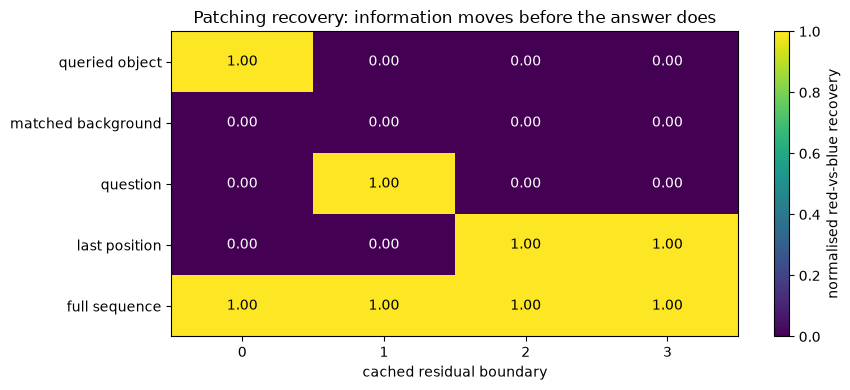

In [15]:
position_sets = {"queried object":[0],"matched background":[1],"question":[4],"last position":[5],"full sequence":list(range(6))}
curves = patch_sweep(initial[:1],initial[1:],position_sets,np.array([0]),np.array([1]))
fig,ax=plt.subplots(figsize=(9,4))
values=np.array(list(curves.values()));im=ax.imshow(values,vmin=0,vmax=1,cmap="viridis",aspect="auto")
ax.set(xticks=range(4),yticks=range(len(curves)),yticklabels=list(curves),xlabel="cached residual boundary",title="Patching recovery: information moves before the answer does")
for row in range(len(curves)):
    for col in range(4):ax.text(col,row,f"{values[row,col]:.2f}",ha="center",va="center",color="white" if values[row,col]<.5 else "black")
fig.colorbar(im,ax=ax,label="normalised red-vs-blue recovery");plt.tight_layout();plt.show()

## Interpreting the result

Full-sequence recovery is an important implementation oracle, not a localisation result: replacing the complete matched state reconstructs the clean computation. The queried visual-token row should succeed only at boundary0; question patching carries the effect at boundary1; answer patching works only after the answer has read it. Background patches are matched in count and fail because this explicit route does not read them. The tiny off-target softmax mass also means an unqueried distractor can have a small influence; do not round every small effect into exactly zero without checking its size.

## Summary of 3️⃣

A failed last-token patch can coexist with a successful full-sequence patch. Neither result alone says visual information is absent.

# 4️⃣ Bridge to real adapters and conditional decoding

> ##### Learning Objectives
>
> - Implement a layout check and activation-conditioned decoder; map the exact contract to released VLM APIs.

### Exercise - implement `decode_visual_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Apply an explicit `(d,vocabulary)` readout to every residual position and return the argmax candidate ID at each position. This simple lens is meaningful only because this organism’s colour readout is declared.

In [16]:
def decode_visual_tokens(hidden, readout):
    return (hidden @ readout).argmax(axis=-1)


tests.test_decode_visual_tokens(decode_visual_tokens)

All tests in test_decode_visual_tokens passed!


<details>
<summary>Hint</summary>

Do not drop the batch or sequence axes. A zero score ties to candidate0, not evidence for red.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_decode_visual_tokens passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `patchscope_readout`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10–15 minutes on this exercise.
> ```

Make a copy of the target prompt’s initial state. Copy **only the first two content coordinates** from one source position into one target visual position, preserving the target’s spatial code. Run the target computation and return its two final answer scores. This is a controlled activation-conditioned decoder, not a learned free-text verbalizer.

In [17]:
def patchscope_readout(source_hidden, target_initial, source_position, target_position):
    target = target_initial.copy()
    target[:,target_position,:2] = source_hidden[:,source_position,:2]
    return run_flow(target)[3][:,5,:2]


tests.test_patchscope_readout(patchscope_readout)

All tests in test_patchscope_readout passed!


<details>
<summary>Hint</summary>

Copying the full source spatial code would change which position the target question attends to, confounding content with position.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_patchscope_readout passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

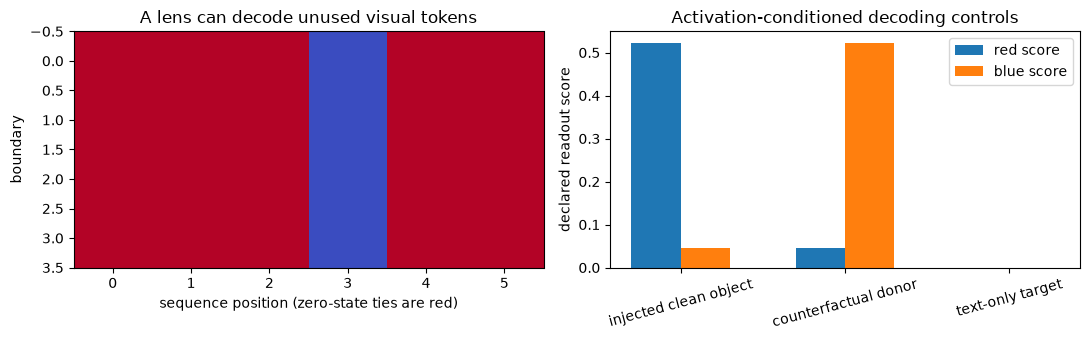

In [18]:
readout = np.zeros((6,2));readout[:2] = np.eye(2)
lens = np.stack([decode_visual_tokens(clean_cache[layer],readout)[0] for layer in range(4)])
inspection = assemble_tokens(np.zeros((1,4,2)),np.array([1]))
conditional = patchscope_readout(clean_cache[0],inspection,0,1)[0]
wrong_source = patchscope_readout(corrupt_cache[0],inspection,0,1)[0]
text_only = run_flow(inspection)[3][0,5,:2]
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].imshow(lens,aspect="auto",cmap="coolwarm_r",vmin=0,vmax=1);axes[0].set(xlabel="sequence position (zero-state ties are red)",ylabel="boundary",title="A lens can decode unused visual tokens")
labels=["injected clean object","counterfactual donor","text-only target"]
axes[1].bar(np.arange(3)-.15,[conditional[0],wrong_source[0],text_only[0]],.3,label="red score");axes[1].bar(np.arange(3)+.15,[conditional[1],wrong_source[1],text_only[1]],.3,label="blue score");axes[1].set(xticks=range(3),xticklabels=labels,ylabel="declared readout score",title="Activation-conditioned decoding controls");axes[1].tick_params(axis="x",labelrotation=15);axes[1].legend()
plt.tight_layout();plt.show()

## The released-model bridge

The reusable contract is: processed inputs and exact image-position mapping; decoder boundary states `(batch,sequence,width)`; a resumable or hook-based replacement at the same boundary; candidate logits; reliable hook removal with `try/finally`. Verify a no-op, full-state clean donor, input nonmutation, batch axes and cached-generation timing before interpreting a real patch. Do not reuse this six-token layout for a processor that expands crops.

| Family | Source-grounded mapping to inspect | What remains unqualified here |
|---|---|---|
| Qwen2.5-VL | Its multimodal processor supplies image grids and image token expansion; inspect its language-decoder hidden-state boundary rather than assuming one patch equals one token. | M-RoPE coordinates, merger geometry, exact installed decoder hook signature and cache lifecycle. |
| PaliGemma | A SigLIP image encoder, multimodal projector and Gemma text backbone; visual-token expansion and prefix attention must be retained. | Image positions, prefix masks, projector-to-LM scaling and candidate-token mapping in a pinned checkpoint. |
| LLaVA-OneVision | SigLIP vision features feed a projector and language model; image/video/crop processing determines the visual sequence. | Any-resolution crop correspondence, image newline/delimiter tokens and full-sequence replacement parity. |
| Molmo | The official code provides image preprocessing/crops, vision features and language generation with image inputs. | Its image-to-token index mapping, checkpoint-specific source path, cache behavior and a native hook/resumption proof. |

These are implementation reading bridges, not adapters claimed to run. The primary links below are the starting points; freeze exact source/checkpoint revisions before a later qualification. For Patchscopes, a real target prompt and model may decode the donor differently from a fixed lens. Free-text feature verbalizers add another inference model and need donor-swap and text-only controls; this notebook implements neither an oracle nor a qualified real-VLM verbalizer.

## Try it yourself

Keep the donor images fixed, but ask about the bottom-right patch instead. Predict which colour is clean and which row of the recovery heatmap should work. This is a changed question and a changed causal target, not just a random seed.

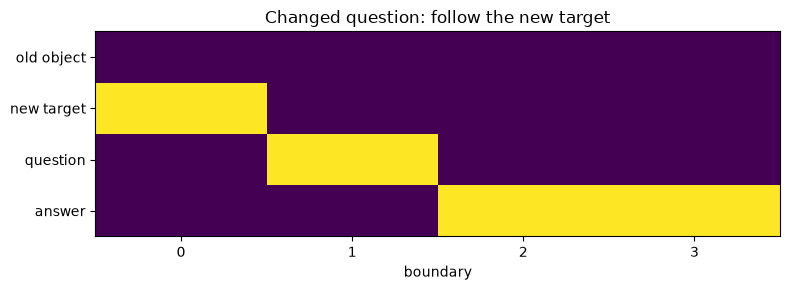

In [19]:
play_initial = assemble_tokens(features,np.array([3,3]))
play_curves = patch_sweep(play_initial[:1],play_initial[1:],{"old object":[0],"new target":[3],"question":[4],"answer":[5]},np.array([1]),np.array([0]))
fig,ax=plt.subplots(figsize=(8,3));ax.imshow(np.array(list(play_curves.values())),aspect="auto",vmin=0,vmax=1);ax.set(yticks=range(4),yticklabels=list(play_curves),xticks=range(4),xlabel="boundary",title="Changed question: follow the new target");plt.tight_layout();plt.show()

## Limitations

The visual encoder is mean pixel colour and the attention route is specified. Its layer0/1 timing is not a measurement of a released VLM. The lens uses known feature coordinates and its zero-state argmax is an arbitrary tie. The two rendered counterfactuals alter a distractor as well as the target; candidate margins and object-only controls show how the known route handles that difference. Native full-sequence hooks/adapters, natural-image evaluation, real Patchscopes/verbalizers and architecture-specific masking/caching remain pending.

The configured requirement IDs remain visible: `vlm.visual_token_flow`, `vlm.full_sequence_patching`, `vlm.qwen25_vl_adapter`, `vlm.paligemma_adapter`, `vlm.llava_onevision_adapter`, `vlm.molmo_adapter`, `vlm.patchscopes_and_verbalizers`. Teaching implementations and CPU fixtures do not promote requirement status, establish a native model result, or confer direct learner acceptance.

# ☆ Bonus

Before changing the recipe, write one prediction about the sign and size of a control difference. After running it, explain a mismatch. A public play outcome is exposed guided practice; changing a seed does not make it an unseen transfer test.

## Further reading

- [Neo et al., Towards Interpreting Visual Information Processing in VLMs](https://arxiv.org/abs/2410.07149): compare their LLaVA object-localisation, visual-token decoding and final-position experiments to our exact route.
- [Qwen2.5-VL documentation](https://huggingface.co/docs/transformers/en/model_doc/qwen2_5_vl) and [PaliGemma documentation](https://huggingface.co/docs/transformers/en/model_doc/paligemma): inspect preprocessing and hidden-state interfaces before choosing hooks.
- [LLaVA-OneVision documentation](https://huggingface.co/docs/transformers/en/model_doc/llava_onevision) and [official Molmo code](https://github.com/allenai/molmo): inspect crop/token expansion rather than assuming a fixed image slice.
- [Ghandeharioun et al., Patchscopes](https://arxiv.org/abs/2401.06102): compare a model-conditioned inspection prompt with a fixed unembedding lens; our two-colour inspection task is deliberately narrower.